# Q11 — L1, L2, and Elastic Net Regularization on a Regression Dataset

**Aim:** Demonstrate how L1 (Lasso), L2 (Ridge), and Elastic Net regularization influence regression coefficients, prediction error, and feature selection.

Uses scikit-learn's built-in diabetes regression dataset (no external download). Standardization is fitted only on training data through pipelines. Change one parameter at a time and compare the numerical results and plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
X, y = load_diabetes(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Dataset:", X.shape, "| train:", X_train.shape, "| test:", X_test.shape)

Dataset: (442, 10) | train: (353, 10) | test: (89, 10)


## 1. Evaluation helper

In [2]:
def evaluate_model(name, estimator):
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    model = estimator[-1] if hasattr(estimator, "steps") else estimator
    return {
        "Model": name,
        "Test MSE": mean_squared_error(y_test, pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test R²": r2_score(y_test, pred),
        "Non-zero coefficients": int(np.sum(np.abs(model.coef_) > 1e-8)),
        "Estimator": estimator
    }

## 2. Baseline comparison: Linear, L1, L2, Elastic Net

In [3]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "L1 / Lasso (alpha=0.1)": make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=50000)),
    "L2 / Ridge (alpha=1.0)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Elastic Net (alpha=0.1, l1_ratio=0.5)": make_pipeline(StandardScaler(), ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=50000))
}
rows, fitted = [], {}
for name, estimator in models.items():
    row = evaluate_model(name, estimator)
    fitted[name] = row.pop("Estimator")
    rows.append(row)
baseline_results = pd.DataFrame(rows).sort_values("Test RMSE")
display(baseline_results.round(4))

,Model,Test MSE,Test RMSE,Test MAE,Test R²,Non-zero coefficients
3,"Elastic Net (alpha=0.1, l1_ratio=0.5)",2866.4613,53.5393,42.8733,0.4590,10
1,L1 / Lasso (alpha=0.1),2884.6243,53.7087,42.8052,0.4555,10
2,L2 / Ridge (alpha=1.0),2892.0146,53.7775,42.8120,0.4541,10
0,Linear Regression,2900.1936,53.8534,42.7941,0.4526,10


## 3. Coefficient comparison

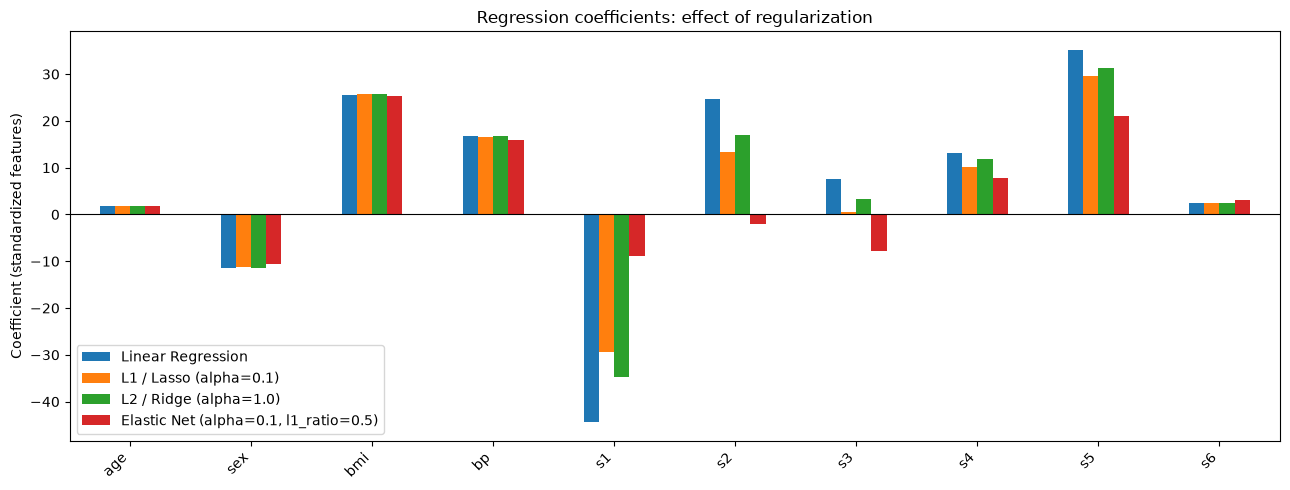

In [4]:
coef_df = pd.DataFrame({name: pipe[-1].coef_ for name, pipe in fitted.items()}, index=X.columns)
ax = coef_df.plot(kind="bar", figsize=(13, 5))
ax.set_title("Regression coefficients: effect of regularization")
ax.set_ylabel("Coefficient (standardized features)")
ax.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 4. Parameter experiment A — change alpha

`alpha` controls regularization strength. Larger alpha generally shrinks coefficient magnitudes more strongly. Lasso can set coefficients exactly to zero; Ridge typically shrinks them without eliminating them.

,Method,alpha,Test RMSE,Test R²,Non-zero coefficients,Coefficient L1 norm,Coefficient L2 norm
0,Lasso,0.001,53.8517,0.4526,10,182.6976,71.4568
1,Ridge,0.001,53.8533,0.4526,10,183.0848,71.6150
2,Elastic Net,0.001,53.8346,0.4530,10,177.0827,69.1156
3,Lasso,0.010,53.8365,0.4529,10,178.8990,69.9103
4,Ridge,0.010,53.8523,0.4526,10,182.7722,71.4836
5,Elastic Net,0.010,53.7405,0.4549,10,141.7417,55.5901
6,Lasso,0.100,53.7087,0.4555,10,140.9604,55.6963
7,Ridge,0.100,53.8429,0.4528,10,179.7379,70.2143
8,Elastic Net,0.100,53.5393,0.4590,10,104.4057,40.7930
9,Lasso,1.000,53.1467,0.4669,9,97.2693,41.1967


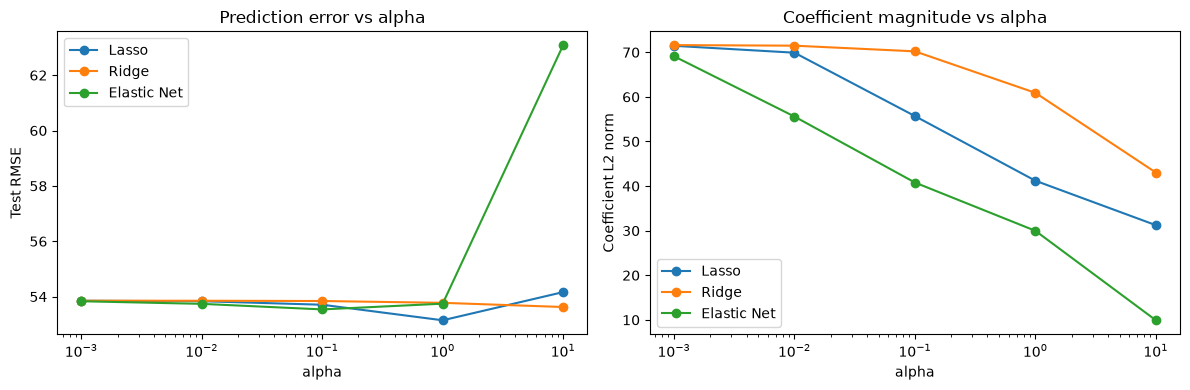

In [5]:
alphas = [0.001, 0.01, 0.1, 1.0, 10.0]
alpha_rows = []
for alpha in alphas:
    candidates = {
        "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=50000)),
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=alpha)),
        "Elastic Net": make_pipeline(StandardScaler(), ElasticNet(alpha=alpha, l1_ratio=0.5, max_iter=50000))
    }
    for method, pipe in candidates.items():
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_test)
        coef = pipe[-1].coef_
        alpha_rows.append({
            "Method": method, "alpha": alpha,
            "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
            "Test R²": r2_score(y_test, pred),
            "Non-zero coefficients": int(np.sum(np.abs(coef) > 1e-8)),
            "Coefficient L1 norm": np.sum(np.abs(coef)),
            "Coefficient L2 norm": np.linalg.norm(coef)
        })
alpha_results = pd.DataFrame(alpha_rows)
display(alpha_results.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for method in alpha_results["Method"].unique():
    part = alpha_results[alpha_results["Method"] == method]
    axes[0].plot(part["alpha"], part["Test RMSE"], marker="o", label=method)
    axes[1].plot(part["alpha"], part["Coefficient L2 norm"], marker="o", label=method)
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("alpha"); ax.legend()
axes[0].set_ylabel("Test RMSE"); axes[0].set_title("Prediction error vs alpha")
axes[1].set_ylabel("Coefficient L2 norm"); axes[1].set_title("Coefficient magnitude vs alpha")
plt.tight_layout(); plt.show()

**Interpretation:** Read the values in the output table and compare error with coefficient shrinkage. Very large alpha can underfit; very small alpha behaves more like an unregularized model. The best alpha is the one supported by observed validation/test performance, not a universal constant.

## 5. Parameter experiment B — change Elastic Net l1_ratio

,Model,l1_ratio,Test RMSE,Test R²,Non-zero coefficients,Coefficient L1 norm
0,Ridge (L2 endpoint),0.00,53.8429,0.4528,10,179.7379
1,Elastic Net (l1_ratio=0.25),0.25,53.5041,0.4597,10,102.4262
2,Elastic Net (l1_ratio=0.5),0.50,53.5393,0.4590,10,104.4057
3,Elastic Net (l1_ratio=0.75),0.75,53.6015,0.4577,9,107.1488
4,Elastic Net (l1_ratio=1.0),1.00,53.7087,0.4555,10,140.9604


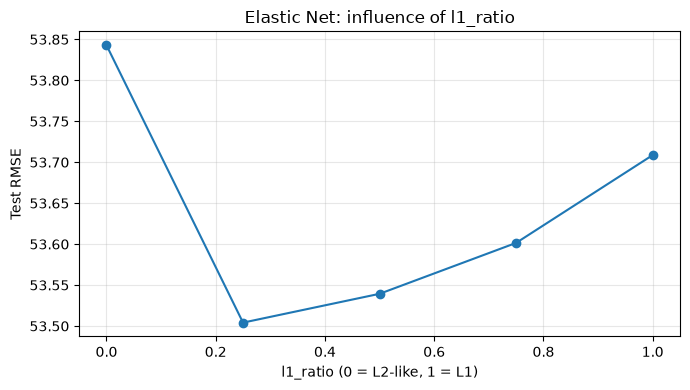

In [6]:
ratios = [0.0, 0.25, 0.5, 0.75, 1.0]
ratio_rows = []
for ratio in ratios:
    if ratio == 0.0:
        pipe = make_pipeline(StandardScaler(), Ridge(alpha=0.1))
        label = "Ridge (L2 endpoint)"
    else:
        pipe = make_pipeline(StandardScaler(), ElasticNet(alpha=0.1, l1_ratio=ratio, max_iter=50000))
        label = f"Elastic Net (l1_ratio={ratio})"
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    coef = pipe[-1].coef_
    ratio_rows.append({
        "Model": label, "l1_ratio": ratio,
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test R²": r2_score(y_test, pred),
        "Non-zero coefficients": int(np.sum(np.abs(coef) > 1e-8)),
        "Coefficient L1 norm": np.sum(np.abs(coef))
    })
ratio_results = pd.DataFrame(ratio_rows)
display(ratio_results.round(4))
plt.figure(figsize=(7, 4))
plt.plot(ratio_results["l1_ratio"], ratio_results["Test RMSE"], marker="o")
plt.xlabel("l1_ratio (0 = L2-like, 1 = L1)")
plt.ylabel("Test RMSE")
plt.title("Elastic Net: influence of l1_ratio")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:** Increasing `l1_ratio` gives more weight to L1 regularization and may increase sparsity (more zero coefficients). `l1_ratio=1` is Lasso; `l1_ratio=0` is represented by Ridge for compatibility. Compare the actual metrics to discuss the effect.

## 6. Conclusion checklist
- Compare RMSE, MAE, and R² across models.
- Use coefficient plots to discuss shrinkage and feature selection.
- Explain the trade-off between coefficient simplicity and predictive error as alpha changes.
- Explain how `l1_ratio` changes the balance of L1 and L2.
- State conclusions based on the observed results from your run.